# Notebook 2: Gene Essentiality Analysis

## Learning Objectives

1. Understand what gene essentiality means
2. Learn how to perform single gene deletions
3. Classify genes as essential or non-essential
4. Save and analyze essentiality results
5. Compare essentiality across different growth conditions

## What is Gene Essentiality?

A gene is **essential** if deleting it severely reduces or eliminates growth. Gene essentiality depends on:
- The growth medium (nutrients available)
- The organism's metabolic capabilities
- Genetic redundancy (alternative pathways)

Essentiality analysis helps us:
- Identify potential drug targets
- Understand metabolic capabilities
- Predict phenotypes
- Guide genetic engineering

---

In [2]:
# Add the parent directory to path
from pathlib import Path
import sys

project_root = Path("..").resolve()
sys.path.insert(0, str(project_root))

# Import our custom functions
from src.model_io import load_model
from src.fba_utils import set_biomass_reaction
from src.gene_essentiality import analyze_gene_essentiality, get_essential_genes, save_essentiality_results

import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

print("✓ Libraries imported!")

✓ Libraries imported!


## Step 1: Load the Model

We start with the same model from Notebook 1.

In [ ]:
# Load model
MODEL_PATH = "../models/paeruginosa_MODEL1507180020.xml"
model = load_model(MODEL_PATH)

# Set biomass objective
BIOMASS_ID = "PA_Biomass6_DM"
model = set_biomass_reaction(model, BIOMASS_ID)

Loading model from: ../models/MODEL1507180020_url.xml
✓ Model loaded: MODEL1507180020
  - Reactions:   1110
  - Metabolites: 879
  - Genes:       1054
✓ Objective set to: PA_Biomass6_DM
  Reaction: Pseudomonas biomass w/ heme
  Direction: 0.0 ≤ flux ≤ 1000.0


## Step 2: Analyze Gene Essentiality

We'll perform single gene deletion analysis. This:
1. Tests each gene individually
2. Deletes the gene (sets its flux to 0)
3. Runs FBA
4. Compares knockout growth to wild-type growth

**Threshold**: We use 1% as the default - if knockout growth drops below 1% of wild-type, the gene is essential.

In [4]:
# Run gene essentiality analysis
# This may take several minutes depending on model size
results = analyze_gene_essentiality(
    model,
    threshold_ratio=0.01,  # 1% threshold
    processes=3  # Use 1 for sequential processing
)

Starting gene essentiality analysis...
  Total genes to test: 1054
  Essentiality threshold: 1.0% of wild-type growth
  Wild-type growth rate: 1.047929

Performing gene deletions...

✓ Analysis complete!
  Essential genes: 166 / 1054 (15.7%)


In [5]:
# View the results
print("\nFirst 10 results:")
print(results.head(20).to_string(index=False))


First 10 results:
 gene_id  wildtype_growth  knockout_growth  growth_ratio  is_essential
{PA2339}         1.047929     1.047929e+00  1.000000e+00         False
{PA3687}         1.047929     1.047929e+00  1.000000e+00         False
{PA3107}         1.047929     1.045592e+00  9.977701e-01         False
{PA4236}         1.047929     1.047929e+00  1.000000e+00         False
{PA0352}         1.047929     1.047929e+00  1.000000e+00         False
{PA1778}         1.047929     1.047929e+00  1.000000e+00         False
{PA1580}         1.047929     1.047929e+00  1.000000e+00         False
{PA1806}         1.047929     5.124397e-15  4.890025e-15          True
{PA3156}         1.047929     1.047929e+00  1.000000e+00         False
{PA4865}         1.047929     1.047929e+00  1.000000e+00         False
{PA2649}         1.047929     9.428866e-01  8.997623e-01         False
{PA4100}         1.047929     1.047929e+00  1.000000e+00         False
{PA3758}         1.047929     1.047929e+00  1.000000e+00  

## Step 3: Summarize Results

In [6]:
# Get summary statistics
essential = results[results['is_essential']]
non_essential = results[~results['is_essential']]

print(f"Total genes tested: {len(results)}")
print(f"Essential genes: {len(essential)} ({len(essential)/len(results)*100:.1f}%)")
print(f"Non-essential genes: {len(non_essential)} ({len(non_essential)/len(results)*100:.1f}%)")

# Show distribution of growth ratios
print("\nGrowth ratio distribution:")
print(results['growth_ratio'].describe())

Total genes tested: 1054
Essential genes: 166 (15.7%)
Non-essential genes: 888 (84.3%)

Growth ratio distribution:
count    1.054000e+03
mean     8.376820e-01
std      3.645015e-01
min     -9.500456e-13
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: growth_ratio, dtype: float64


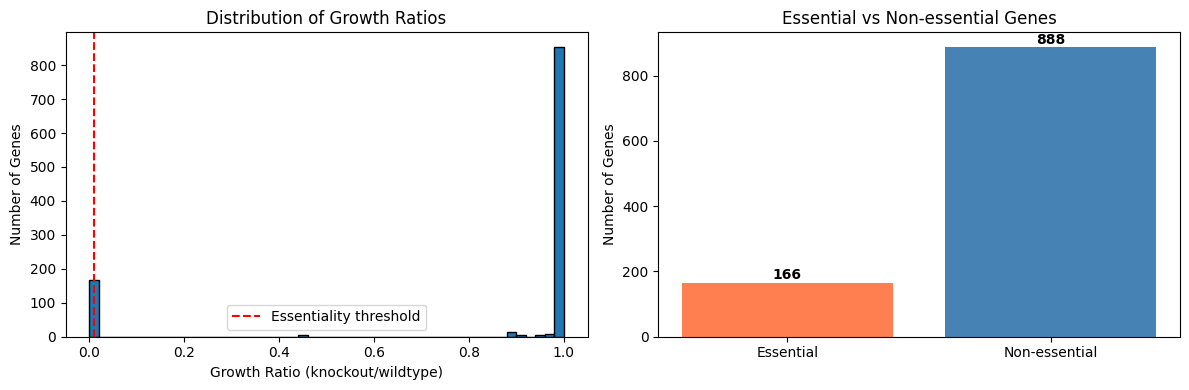

In [7]:
# Visualize the distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# Histogram of growth ratios
ax1.hist(results['growth_ratio'], bins=50, edgecolor='black')
ax1.axvline(x=0.01, color='red', linestyle='--', label='Essentiality threshold')
ax1.set_xlabel('Growth Ratio (knockout/wildtype)')
ax1.set_ylabel('Number of Genes')
ax1.set_title('Distribution of Growth Ratios')
ax1.legend()

# Bar chart comparing essential vs non-essential
counts = [len(essential), len(non_essential)]
labels = ['Essential', 'Non-essential']
ax2.bar(labels, counts, color=['coral', 'steelblue'])
ax2.set_ylabel('Number of Genes')
ax2.set_title('Essential vs Non-essential Genes')
for i, v in enumerate(counts):
    ax2.text(i, v + 10, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## Step 4: Examine Essential Genes

In [8]:
# Get the set of essential genes
from src.gene_essentiality import get_essential_genes

essential_gene_set = get_essential_genes(results)

print("Essential genes (showing first 20):")
for i, gene in enumerate(list(essential_gene_set)[:20]):
    print(f"{i+1}. {gene}")


Essential genes (showing first 20):
1. PA0006
2. PA5066
3. PA3111
4. PA1843
5. PA5552
6. PA3651
7. PA4054
8. PA0393
9. PA0724
10. PA3735
11. PA1681
12. PA0330
13. PA4443
14. PA1614
15. PA4729
16. PA5259
17. PA5320
18. PA4748
19. PA5175
20. PA3807


## Step 5: Save Results

Let's save the results to a CSV file for future reference.

In [9]:
# Save to CSV
save_essentiality_results(
    results,
    "../results/essentiality/gene_essentiality_default_medium.csv",
    condition_name="default_medium"
)

print("\n✓ Results saved!")

✓ Results saved to: ../results/essentiality/gene_essentiality_default_medium.csv

✓ Results saved!


## Summary

In this notebook, you learned:

1. ✓ What gene essentiality means and why it matters
2. ✓ How to perform single gene deletion analysis
3. ✓ How to interpret essentiality results
4. ✓ How to visualize the distribution of gene effects
5. ✓ How to save results for further analysis

### Key Insights:

- Most genes are **non-essential** under most conditions
- Essential genes are often involved in:
  - Central metabolism
  - Biomass precursor biosynthesis
  - DNA replication and cell division
- Gene essentiality is **condition-dependent**

### Next Steps:

In Notebook 3, we'll compare predicted essential genes with experimental data to validate our model predictions.

---